# EN4554 – Assignment 2: Convolutional Neural Networks

**Name:** Praveen V.V.J.  &nbsp;&nbsp; **Index No:** `220491B`  
**GitHub:** https://github.com/john-praveen/EN4554-Assignment-2

**Contents:** Setup · Task 1 Backpropagation · Task 2 Optimizers · Task 3 Regularization & residual connections · Task 4 Best CNN (optional)

## Setup

This section covers the environment, the fixed seeds, and the CIFAR-10 data pipeline. CIFAR-10 is split 45k train / 5k validation, and each channel is normalised with the **training-split** mean and std. The test set is not touched until Task 4.

In [1]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


In [2]:
from datasets import load_dataset

train_data = load_dataset('uoft-cs/cifar10', split='train')
images = [np.array(img) for img in train_data['img']]
X = torch.tensor(np.stack(images)).permute(0, 3, 1, 2).float() / 255
y = torch.tensor(train_data['label'])

perm = torch.randperm(50000)
X_tr, y_tr = X[perm[:45000]], y[perm[:45000]]
X_va, y_va = X[perm[45000:]], y[perm[45000:]]

mean = X_tr.mean(dim=(0, 2, 3), keepdim=True)
std = X_tr.std(dim=(0, 2, 3), keepdim=True)

X_tr = ((X_tr - mean) / std).to(device)
X_va = ((X_va - mean) / std).to(device)
y_tr = y_tr.to(device)
y_va = y_va.to(device)
print(X_tr.shape, X_va.shape)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


torch.Size([45000, 3, 32, 32]) torch.Size([5000, 3, 32, 32])


In [3]:
def accuracy(model, X, y, bs=1000):
    model.eval()
    correct = 0
    with torch.no_grad():
        for i in range(0, len(X), bs):
            predictions = model(X[i:i + bs]).argmax(1)
            correct += (predictions == y[i:i + bs]).sum().item()
    return correct / len(X)

**Data source.** This is the standard CIFAR-10 training set (50,000 images, 10 classes), loaded with the Hugging Face `datasets` library instead of `torchvision.datasets.CIFAR10`. The download server that `torchvision` uses ran at about 66 kB/s on Colab, an estimated 40 minutes for the 170 MB archive, so I used a faster mirror of the same data. The mean and std come from the 45k training images only, and the test set is left untouched until Task 4.

## Task 1: Backpropagation

### 1(a) Layers with explicit forward and backward

Each layer stores what it needs in `forward` and uses it in `backward`, which receives `dout`, the gradient of the loss with respect to the layer's output, and returns the gradient with respect to its input. The gradients are derived by hand, with no autograd.

| Layer | Forward | Backward |
|---|---|---|
| Linear | `out = x @ W + b` | `dW = xᵀ @ dout`, `db = sum(dout)`, `dx = dout @ Wᵀ` |
| ReLU | `out = max(0, x)` | `dx = dout * (x > 0)` |
| Sigmoid (used in 1d) | `out = 1 / (1 + e^-x)` | `dx = dout * out * (1 - out)` |
| Softmax + cross-entropy | `L = -mean(log softmax(z)[y])` | `dz = (softmax(z) - onehot(y)) / N` |

The softmax and the cross-entropy are combined into one layer because their combined gradient simplifies to `(p - onehot) / N`. Linear weights use He initialisation, `N(0, 2/n_in)`.

In [4]:
class Linear:
    def __init__(self, n_in, n_out):
        self.W = torch.randn(n_in, n_out, device=device) * (2 / n_in) ** 0.5
        self.b = torch.zeros(n_out, device=device)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(0)
        return dout @ self.W.T

class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask

class Sigmoid:
    def forward(self, x):
        self.out = 1 / (1 + torch.exp(-x))
        return self.out

    def backward(self, dout):
        return dout * self.out * (1 - self.out)

class SoftmaxCE:
    def forward(self, logits, y):
        z = logits - logits.max(1, keepdim=True).values
        logp = z - z.logsumexp(1, keepdim=True)
        self.p = logp.exp()
        self.y = y
        rows = torch.arange(len(y), device=y.device)
        return -logp[rows, y].mean()

    def backward(self):
        rows = torch.arange(len(self.y), device=self.y.device)
        d = self.p.clone()
        d[rows, self.y] -= 1
        return d / len(self.y)

class MLP:
    def __init__(self, sizes, act=ReLU):
        self.layers = []
        self.linears = []
        for i in range(len(sizes) - 1):
            linear = Linear(sizes[i], sizes[i + 1])
            self.layers.append(linear)
            self.linears.append(linear)
            if i < len(sizes) - 2:
                self.layers.append(act())
        self.loss_fn = SoftmaxCE()

    def logits(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def forward(self, x, y):
        return self.loss_fn.forward(self.logits(x), y)

    def backward(self):
        d = self.loss_fn.backward()
        for layer in reversed(self.layers):
            d = layer.backward(d)

### 1(b) Gradient check

A small MLP (3072-32-16-10) is checked in float64 on 16 validation images. The manual gradients are compared with:
1. **autograd**, on every entry, using `torch.allclose`;
2. **centred finite differences**, `(L(w+ε) − L(w−ε)) / 2ε` with `ε = 1e-5`, on 50 randomly chosen entries of each parameter tensor. Checking every entry would take too long.

The relative error is `‖a − b‖ / (‖a‖ + ‖b‖)`.

In [5]:
set_seed()
xs = X_va[:16].reshape(16, -1).cpu().double()
ys = y_va[:16].cpu()
net = MLP([3072, 32, 16, 10])
for layer in net.linears:
    layer.W = layer.W.cpu().double()
    layer.b = layer.b.cpu().double()

net.forward(xs, ys)
net.backward()

weights = []
biases = []
for layer in net.linears:
    weights.append(layer.W.clone().requires_grad_())
    biases.append(layer.b.clone().requires_grad_())

h = xs
for k in range(len(weights)):
    h = h @ weights[k] + biases[k]
    if k < len(weights) - 1:
        h = F.relu(h)
F.cross_entropy(h, ys).backward()

def finite_diff(param, indices, eps=1e-5):
    flat = param.view(-1)
    grads = []
    for i in indices:
        old = flat[i].item()
        flat[i] = old + eps
        loss_plus = net.forward(xs, ys).item()
        flat[i] = old - eps
        loss_minus = net.forward(xs, ys).item()
        flat[i] = old
        grads.append((loss_plus - loss_minus) / (2 * eps))
    return torch.tensor(grads, dtype=torch.float64)

def relative_error(a, b):
    return ((a - b).norm() / (a.norm() + b.norm())).item()

checks = []
for k, layer in enumerate(net.linears):
    checks.append((f'W{k + 1}', layer.W, layer.dW, weights[k].grad))
    checks.append((f'b{k + 1}', layer.b, layer.db, biases[k].grad))

for name, param, manual, auto in checks:
    idx = torch.randperm(param.numel())[:50]
    fd = finite_diff(param, idx)
    manual_subset = manual.reshape(-1)[idx]

    err_auto = relative_error(manual, auto)
    ok_auto = torch.allclose(manual, auto, rtol=1e-6, atol=1e-9)
    err_fd = relative_error(manual_subset, fd)
    ok_fd = torch.allclose(manual_subset, fd, rtol=1e-4, atol=1e-7)
    print(f'{name}   vs autograd: {err_auto:.2e}, allclose {ok_auto}   vs finite diff: {err_fd:.2e}, allclose {ok_fd}')

W1   vs autograd: 9.85e-17, allclose True   vs finite diff: 1.64e-10, allclose True
b1   vs autograd: 8.10e-17, allclose True   vs finite diff: 1.92e-10, allclose True
W2   vs autograd: 7.38e-17, allclose True   vs finite diff: 7.50e-11, allclose True
b2   vs autograd: 9.05e-17, allclose True   vs finite diff: 6.07e-11, allclose True
W3   vs autograd: 5.22e-17, allclose True   vs finite diff: 9.42e-11, allclose True
b3   vs autograd: 5.56e-17, allclose True   vs finite diff: 9.16e-11, allclose True


**Interpretation (1b).** The manual gradients match autograd to a relative error of about 1e-16, which is float64 machine precision, and `torch.allclose` returns `True` for every parameter tensor. They also match the centred finite differences to about 1e-10. That is the size expected from the truncation error of the centred difference, which is O(ε²) = 1e-10 for ε = 1e-5, so the remaining gap comes from the numerical estimate and not from my backward code. Autograd is exact, which is why it agrees far more closely than the finite differences do. Both checks pass for the weights and biases of all three layers, so the `Linear`, `ReLU` and `SoftmaxCE` backward passes are correct, including the combined softmax-and-cross-entropy gradient `(p − onehot) / N`.

### 1(c) Training the MLP with SGD

A 3072-256-128-10 MLP is trained on flattened, normalised images with plain mini-batch SGD (learning rate 0.05, batch size 128, 15 epochs). The update is applied by hand, `W -= lr * dW`.

epoch  1  train loss 1.730  val acc 0.4138
epoch  2  train loss 1.464  val acc 0.4770
epoch  3  train loss 1.351  val acc 0.4848
epoch  4  train loss 1.263  val acc 0.4930
epoch  5  train loss 1.192  val acc 0.5008
epoch  6  train loss 1.130  val acc 0.4864
epoch  7  train loss 1.073  val acc 0.4940
epoch  8  train loss 1.021  val acc 0.5164
epoch  9  train loss 0.968  val acc 0.5064
epoch 10  train loss 0.918  val acc 0.5106
epoch 11  train loss 0.870  val acc 0.4964
epoch 12  train loss 0.827  val acc 0.5164
epoch 13  train loss 0.789  val acc 0.4824
epoch 14  train loss 0.748  val acc 0.4894
epoch 15  train loss 0.712  val acc 0.4908


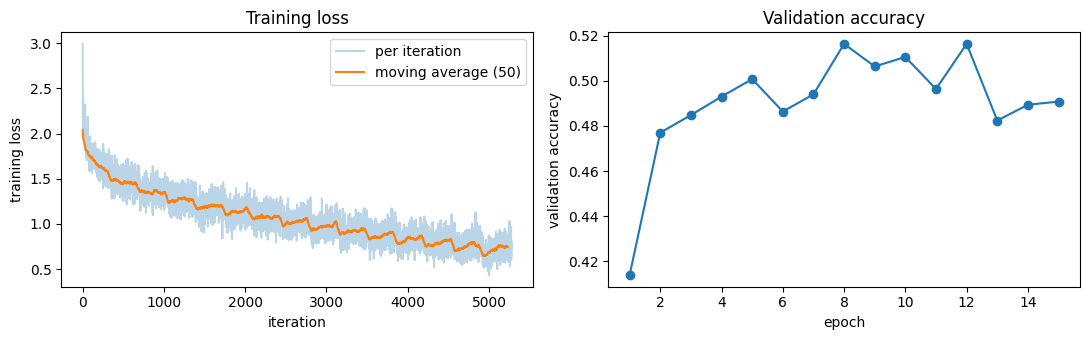

Final validation accuracy: 0.4908


In [6]:
set_seed()
Xf_tr = X_tr.reshape(len(X_tr), -1)
Xf_va = X_va.reshape(len(X_va), -1)
net = MLP([3072, 256, 128, 10])

lr = 0.05
bs = 128
epochs = 15
losses = []
val_accs = []

for ep in range(epochs):
    perm = torch.randperm(len(Xf_tr), device=device)
    epoch_losses = []
    for i in range(0, len(perm), bs):
        idx = perm[i:i + bs]
        loss = net.forward(Xf_tr[idx], y_tr[idx])
        net.backward()
        for layer in net.linears:
            layer.W -= lr * layer.dW
            layer.b -= lr * layer.db
        epoch_losses.append(loss.item())
    losses += epoch_losses

    predictions = net.logits(Xf_va).argmax(1)
    val_accs.append((predictions == y_va).float().mean().item())
    print(f'epoch {ep + 1:2d}  train loss {np.mean(epoch_losses):.3f}  val acc {val_accs[-1]:.4f}')

smooth = np.convolve(losses, np.ones(50) / 50, mode='valid')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(losses, alpha=0.3, label='per iteration')
ax[0].plot(smooth, label='moving average (50)')
ax[0].set_xlabel('iteration')
ax[0].set_ylabel('training loss')
ax[0].set_title('Training loss')
ax[0].legend()
ax[1].plot(range(1, epochs + 1), val_accs, marker='o')
ax[1].set_xlabel('epoch')
ax[1].set_ylabel('validation accuracy')
ax[1].set_title('Validation accuracy')
plt.tight_layout()
plt.show()
print(f'Final validation accuracy: {val_accs[-1]:.4f}')

**Interpretation (1c).** The training loss falls steadily, from 1.73 in epoch 1 to 0.71 in epoch 15, so the hand-written backprop and SGD update do optimise the network. Validation accuracy rises quickly to about 48% after two epochs and then stops improving. From epoch 5 onward it stays between roughly 48% and 52%, while the training loss keeps dropping. The final validation accuracy after epoch 15 is **49.1%**, and the best epoch was 51.6%. I report the final-epoch value because choosing the best epoch on the same 5k images would be optimistic.

The flat validation curve next to a falling training loss is the start of overfitting. The MLP treats the image as a flat vector of 3072 numbers, so it has no built-in notion of neighbouring pixels or translation. It can only fit the training set by memorising it, and that does not transfer to new images. The epoch-to-epoch swings of up to 2–3% come from two sources. One is the constant learning rate of 0.05, which keeps the weights moving. The other is the small validation set: with 5,000 images, the standard error of an accuracy near 50% is already about 0.7%. These numbers are the reason the later tasks use convolutional networks.

The 15 epochs are a fixed budget that I chose without tuning. It is long enough for the training loss to fall clearly and for the validation curve to flatten, and short enough to leave GPU time for the later tasks. Because validation accuracy stopped improving by epoch 5, more epochs would only widen the gap between training and validation performance.


### 1(d) Per-layer gradient norms in a 10-layer MLP at initialisation

A 10-layer MLP (3072 → 256 × 9 → 10, so 10 `Linear` layers) is built with sigmoid and with ReLU. The seed and the He initialisation are the same for both. The only difference is the activation. One backward pass is run on a batch of 256 training images, and the Frobenius norm of `dW` is recorded for each layer.

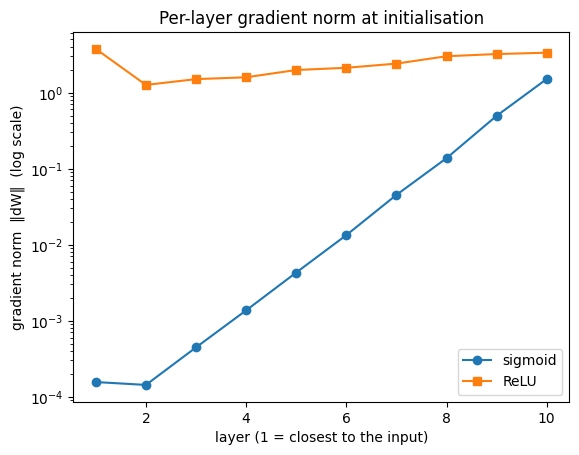

layer  1   sigmoid 1.56e-04   ReLU 3.76e+00
layer  2   sigmoid 1.43e-04   ReLU 1.26e+00
layer  3   sigmoid 4.45e-04   ReLU 1.51e+00
layer  4   sigmoid 1.37e-03   ReLU 1.59e+00
layer  5   sigmoid 4.30e-03   ReLU 1.99e+00
layer  6   sigmoid 1.33e-02   ReLU 2.12e+00
layer  7   sigmoid 4.51e-02   ReLU 2.41e+00
layer  8   sigmoid 1.37e-01   ReLU 3.01e+00
layer  9   sigmoid 4.95e-01   ReLU 3.22e+00
layer 10   sigmoid 1.51e+00   ReLU 3.35e+00


In [7]:
def layer_grad_norms(act):
    set_seed()
    net = MLP([3072] + [256] * 9 + [10], act)
    net.forward(Xf_tr[:256], y_tr[:256])
    net.backward()
    norms = []
    for layer in net.linears:
        norms.append(layer.dW.norm().item())
    return norms

g_sig = layer_grad_norms(Sigmoid)
g_relu = layer_grad_norms(ReLU)

plt.semilogy(range(1, 11), g_sig, marker='o', label='sigmoid')
plt.semilogy(range(1, 11), g_relu, marker='s', label='ReLU')
plt.xlabel('layer (1 = closest to the input)')
plt.ylabel('gradient norm  ‖dW‖  (log scale)')
plt.title('Per-layer gradient norm at initialisation')
plt.legend()
plt.show()

for i in range(10):
    print(f'layer {i + 1:2d}   sigmoid {g_sig[i]:.2e}   ReLU {g_relu[i]:.2e}')

**Interpretation (1d).** With sigmoid, the gradient norm shrinks by about 4 orders of magnitude from the output layer (1.5) to the layers near the input (about 1.5e-4). It falls by roughly a factor of 3 for every layer the gradient travels backwards, which is why the sigmoid line on the log plot is nearly straight. With ReLU the norms stay in the range 1.3 to 3.8 across all ten layers, so no layer is starved.

The cause is the backward pass. At each layer the gradient is multiplied by `Wᵀ` and by the derivative of the activation.
- **Sigmoid:** its derivative is at most 0.25, and about 0.2 for typical pre-activations. The He-initialised `Wᵀ` scales the gradient by about √2. Together that gives a factor of about √2 × 0.22 ≈ 0.3 per layer, or roughly 1/3. This matches the measured ratio between neighbouring layers, which is about 3.0 to 3.6. Over 9 layers the gradient shrinks by about 3⁹ ≈ 2×10⁴. This is the vanishing-gradient problem, and the early layers would learn extremely slowly.
- **ReLU:** its derivative is 1 for active units and 0 for inactive ones, and about half the units are active. The mask removes roughly half of the signal power, which cancels the √2 gain from He initialisation, so the gradient keeps about the same size from layer to layer. This is exactly what He initialisation is designed for.

Layer 1 sits slightly above layer 2 for both activations. Its weight matrix is 3072 × 256, so it has more entries and a larger Frobenius norm. ReLU gradients also grow slightly towards the output, because `dW` also depends on the size of the layer inputs.

## Task 2: Optimizers

### 2(a) SGD with momentum and Adam as `torch.optim.Optimizer` subclasses

Update rules, where `g` is the gradient, `lr` the learning rate and `t` the step count:

**SGD with momentum** (the PyTorch convention, with no dampening):
`buf = momentum * buf + g`, then `w = w - lr * buf`. On the first step `buf = g`.

**Adam** with bias correction:
`m = β1 * m + (1 - β1) * g`
`v = β2 * v + (1 - β2) * g²`
`m̂ = m / (1 - β1ᵗ)`, `v̂ = v / (1 - β2ᵗ)`
`w = w - lr * m̂ / (√v̂ + ε)`

Without the bias correction, `m` and `v` start at zero and are biased towards zero in the first steps. Dividing by `(1 - βᵗ)` removes that bias.

To test them, two copies of the same small network start from identical weights and see identical mini-batches. One copy uses my optimizer and the other uses the PyTorch one. After 20 steps the parameters are compared.

In [8]:
class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if group['momentum'] > 0:
                    state = self.state[p]
                    if 'buf' not in state:
                        state['buf'] = g.clone()
                    else:
                        state['buf'].mul_(group['momentum']).add_(g)
                    g = state['buf']
                p.add_(g, alpha=-group['lr'])

class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            b1, b2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue
                state = self.state[p]
                if not state:
                    state['t'] = 0
                    state['m'] = torch.zeros_like(p)
                    state['v'] = torch.zeros_like(p)
                state['t'] += 1
                t = state['t']
                state['m'].mul_(b1).add_(p.grad, alpha=1 - b1)
                state['v'].mul_(b2).addcmul_(p.grad, p.grad, value=1 - b2)
                m_hat = state['m'] / (1 - b1 ** t)
                v_hat = state['v'] / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(group['eps']), value=-group['lr'])

def make_optimizer(name, params, lr):
    if name == 'SGD':
        return MySGD(params, lr=lr)
    if name == 'SGD + momentum':
        return MySGD(params, lr=lr, momentum=0.9)
    return MyAdam(params, lr=lr)

In [9]:
import copy

def run_steps(model, opt, steps=20):
    set_seed()
    for _ in range(steps):
        idx = torch.randint(0, len(X_tr), (128,), device=device)
        loss = F.cross_entropy(model(X_tr[idx]), y_tr[idx])
        opt.zero_grad()
        loss.backward()
        opt.step()

def max_difference(model_a, model_b):
    biggest = 0
    for pa, pb in zip(model_a.parameters(), model_b.parameters()):
        biggest = max(biggest, (pa - pb).abs().max().item())
    return biggest

def compare(label, mine, reference, **kwargs):
    set_seed()
    base = nn.Sequential(nn.Flatten(), nn.Linear(3072, 64), nn.ReLU(), nn.Linear(64, 10)).to(device)
    a = copy.deepcopy(base)
    b = copy.deepcopy(base)
    run_steps(a, mine(a.parameters(), **kwargs))
    run_steps(b, reference(b.parameters(), **kwargs))

    diff = max_difference(a, b)
    moved = max_difference(a, base)
    same = True
    for pa, pb in zip(a.parameters(), b.parameters()):
        if not torch.allclose(pa, pb, rtol=1e-5, atol=1e-6):
            same = False
    print(f'{label:30s} max |difference| = {diff:.2e}   max weight change = {moved:.2e}   allclose: {same}')

compare('SGD (lr=0.01)', MySGD, torch.optim.SGD, lr=0.01)
compare('SGD momentum 0.9 (lr=0.01)', MySGD, torch.optim.SGD, lr=0.01, momentum=0.9)
compare('Adam (lr=1e-3)', MyAdam, torch.optim.Adam, lr=1e-3)
compare('Adam (lr=1e-2)', MyAdam, torch.optim.Adam, lr=1e-2)

SGD (lr=0.01)                  max |difference| = 0.00e+00   max weight change = 9.49e-03   allclose: True
SGD momentum 0.9 (lr=0.01)     max |difference| = 0.00e+00   max weight change = 4.91e-02   allclose: True
Adam (lr=1e-3)                 max |difference| = 2.14e-08   max weight change = 1.71e-02   allclose: True
Adam (lr=1e-2)                 max |difference| = 3.43e-07   max weight change = 1.54e-01   allclose: True


**Interpretation (2a).** My `MySGD` matches `torch.optim.SGD` exactly, with a maximum parameter difference of 0, both with and without momentum. My `MyAdam` matches `torch.optim.Adam` to 2e-8 (lr = 1e-3) and 3e-7 (lr = 1e-2), and `torch.allclose` returns `True` in all four cases. The "max weight change" column shows that the weights really moved during the 20 steps, so the match is not trivial. The small Adam differences are floating-point rounding. PyTorch computes the denominator as `√v / √(1 − β2ᵗ) + ε`, while I compute `√(v / (1 − β2ᵗ)) + ε`. The two are equal in exact arithmetic but round differently in float32, and the gap is larger at the higher learning rate because the weights move further. SGD has no square root or division, so the two implementations perform the same operations and agree bit for bit.

### 2(b) Trajectories on an ill-conditioned quadratic

`f(x, y) = ½ (x² + 50 y²)` has gradient `(x, 50y)`. It is 50 times steeper in `y` than in `x`, so the contours are long thin ellipses. All three methods start at `(8, 1)` and take 100 steps. My own optimizer classes from 2(a) are used.

- **SGD**: `lr = 0.03`. Plain gradient descent is stable only for `lr < 2/50 = 0.04`, so this is close to the largest usable value.
- **SGD with momentum**: the same `lr = 0.03`, with `momentum = 0.9`.
- **Adam**: `lr = 0.3`.

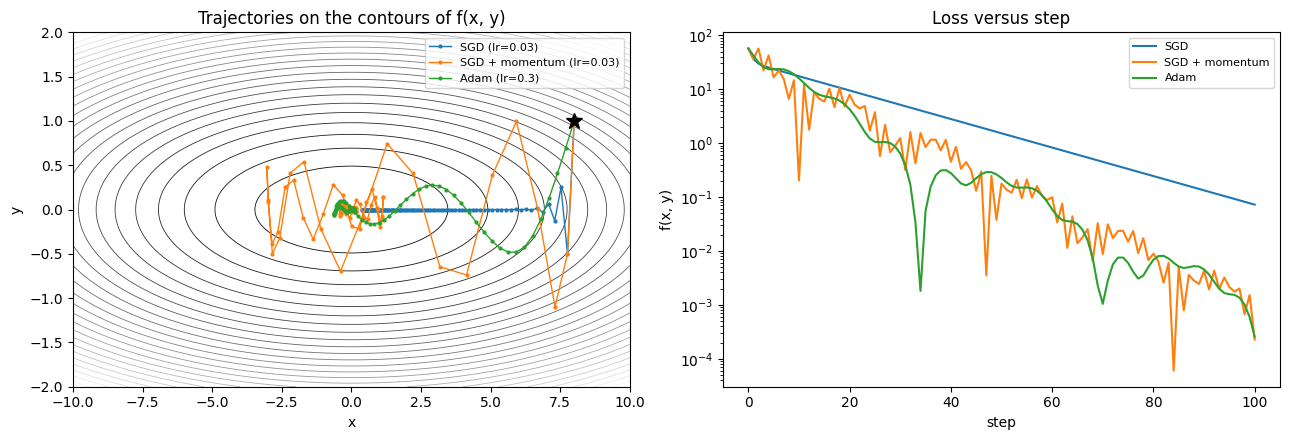

SGD              final point (+0.3804, +0.0000)   final f = 7.236e-02
SGD + momentum   final point (-0.0198, -0.0011)   final f = 2.275e-04
Adam             final point (+0.0194, -0.0016)   final f = 2.562e-04


In [10]:
lr_2b = {'SGD': 0.03, 'SGD + momentum': 0.03, 'Adam': 0.3}

def run_trajectory(name, steps=100, start=(8.0, 1.0)):
    p = torch.tensor(start, requires_grad=True)
    opt = make_optimizer(name, [p], lr_2b[name])
    path = [p.detach().clone().numpy()]
    for _ in range(steps):
        f = 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)
        opt.zero_grad()
        f.backward()
        opt.step()
        path.append(p.detach().clone().numpy())
    return np.array(path)

def f_values(path):
    return 0.5 * (path[:, 0] ** 2 + 50 * path[:, 1] ** 2)

paths = {}
for name in lr_2b:
    paths[name] = run_trajectory(name)

gx, gy = np.meshgrid(np.linspace(-10, 10, 400), np.linspace(-2, 2, 400))
gz = 0.5 * (gx ** 2 + 50 * gy ** 2)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].contour(gx, gy, gz, levels=25, cmap='gray', linewidths=0.6)
for name in paths:
    label = f'{name} (lr={lr_2b[name]})'
    ax[0].plot(paths[name][:, 0], paths[name][:, 1], marker='.', markersize=4, linewidth=1, label=label)
ax[0].plot(8, 1, 'k*', markersize=12)
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].set_title('Trajectories on the contours of f(x, y)')
ax[0].legend(fontsize=8)

for name in paths:
    ax[1].semilogy(f_values(paths[name]) + 1e-12, label=name)
ax[1].set_xlabel('step')
ax[1].set_ylabel('f(x, y)')
ax[1].set_title('Loss versus step')
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

for name in paths:
    final = paths[name][-1]
    print(f'{name:16s} final point ({final[0]:+.4f}, {final[1]:+.4f})   final f = {f_values(paths[name])[-1]:.3e}')

**Interpretation (2b).** The three methods behave very differently on this ill-conditioned bowl, which is 50 times steeper in `y` than in `x`.

- **SGD** removes the `y` error in a few steps, because with `lr = 0.03` each step multiplies `y` by `1 − 50 × 0.03 = −0.5`. The step size is limited by the steep direction (`lr < 0.04`). In the flat `x` direction each step multiplies `x` by only `1 − 0.03 = 0.97`, so after 100 steps `x = 8 × 0.97¹⁰⁰ ≈ 0.38`, which is exactly the final point (+0.3804, 0). This gives the straight line along the valley in the contour plot and the straight line on the log plot, which means steady but slow linear convergence. The final f is 7.2e-2.
- **SGD with momentum** (same learning rate) accumulates velocity along the consistent `x` direction, so its effective step there is about `lr / (1 − β) = 0.3`, ten times larger. It overshoots and oscillates across the valley, which gives the orange zig-zag and the spikes in the loss curve: momentum is not a descent method, so f can go up for a step. Even so, it ends at f = 2.3e-4, about 300 times lower than SGD.
- **Adam** divides each coordinate's step by the running RMS of its own gradient, so the huge gradient in `y` and the small one in `x` are scaled to similar step sizes. Its path starts diagonally and spirals in, with a decaying oscillation in `y`. The step size is about `lr = 0.3` per coordinate at first, which is large compared with the valley width and causes the overshoot. It ends at f = 2.6e-4, about the same as momentum.

The ranking depends on the learning rates I chose, which I did not tune. SGD's rate was set near its stability limit, which is the best plain SGD can do here. The comparison therefore shows that both momentum and Adam help with ill-conditioning by moving faster along the flat direction. SGD cannot do this because the steep direction forces a small learning rate.

### 2(c) Optimizer sensitivity on a small CNN

A small CNN (three 3×3 conv layers with 32, 64 and 128 channels, each followed by ReLU and 2×2 max-pooling, then one linear layer; about 114k parameters, no batch norm) is trained for 10 epochs with batch size 128 for every optimizer and learning-rate pair. All runs use the same seed, so the initial weights and the batch order are the same and only the optimizer changes. The optimizers are my `MySGD` and `MyAdam` from 2(a).

| Optimizer | Learning rates |
|---|---|
| SGD | 0.001, 0.01, 0.1 |
| SGD + momentum 0.9 | 0.001, 0.01, 0.1 |
| Adam | 0.0001, 0.001, 0.01 |

The rates are a decade apart, so they show how sensitive each optimizer is. A run's score is its validation accuracy after the last epoch, which avoids picking the best epoch on the validation set.

In [11]:
def make_cnn():
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(128 * 4 * 4, 10))

def train_cnn(name, lr, epochs=10, bs=128):
    set_seed()
    model = make_cnn().to(device)
    opt = make_optimizer(name, model.parameters(), lr)
    train_losses = []
    val_accs = []
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(X_tr), device=device)
        total = 0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            loss = F.cross_entropy(model(X_tr[idx]), y_tr[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(idx)
        train_losses.append(total / len(perm))
        val_accs.append(accuracy(model, X_va, y_va))
    return train_losses, val_accs

print('CNN parameters:', sum(p.numel() for p in make_cnn().parameters()))

CNN parameters: 113738


In [12]:
learning_rates = {
    'SGD': [0.001, 0.01, 0.1],
    'SGD + momentum': [0.001, 0.01, 0.1],
    'Adam': [1e-4, 1e-3, 1e-2],
}

results = {}
for name in learning_rates:
    for lr in learning_rates[name]:
        train_losses, val_accs = train_cnn(name, lr)
        results[(name, lr)] = (train_losses, val_accs)
        print(f'{name:15s} lr={lr:<7g} final train loss {train_losses[-1]:.3f}   final val acc {val_accs[-1]:.4f}')

SGD             lr=0.001   final train loss 1.872   final val acc 0.3574
SGD             lr=0.01    final train loss 1.127   final val acc 0.6046
SGD             lr=0.1     final train loss 0.499   final val acc 0.7274
SGD + momentum  lr=0.001   final train loss 1.103   final val acc 0.6018
SGD + momentum  lr=0.01    final train loss 0.445   final val acc 0.7502
SGD + momentum  lr=0.1     final train loss 1.191   final val acc 0.5686
Adam            lr=0.0001  final train loss 1.047   final val acc 0.6186
Adam            lr=0.001   final train loss 0.352   final val acc 0.7530
Adam            lr=0.01    final train loss 1.272   final val acc 0.5368


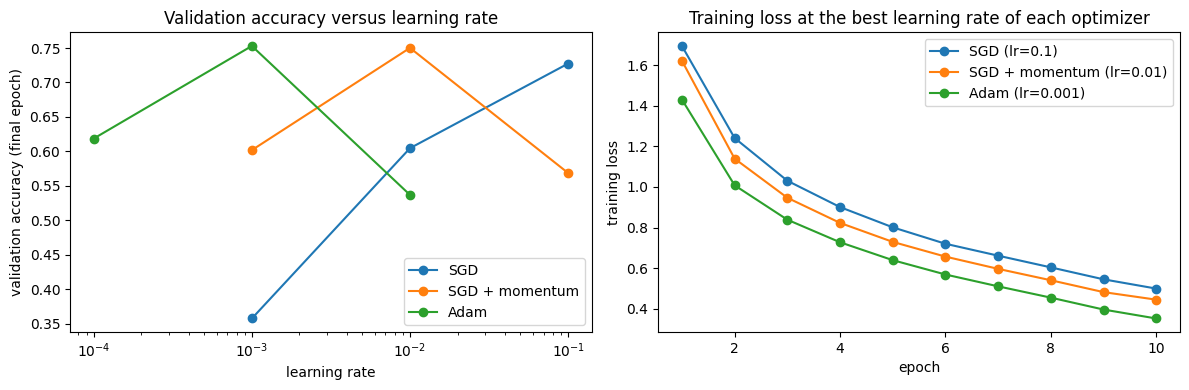

In [13]:
best_lr = {}

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name in learning_rates:
    lrs = learning_rates[name]
    accs = []
    for lr in lrs:
        accs.append(results[(name, lr)][1][-1])
    ax[0].plot(lrs, accs, marker='o', label=name)
    best_lr[name] = lrs[accs.index(max(accs))]
ax[0].set_xscale('log')
ax[0].set_xlabel('learning rate')
ax[0].set_ylabel('validation accuracy (final epoch)')
ax[0].set_title('Validation accuracy versus learning rate')
ax[0].legend()

for name in best_lr:
    train_losses = results[(name, best_lr[name])][0]
    ax[1].plot(range(1, len(train_losses) + 1), train_losses, marker='o', label=f'{name} (lr={best_lr[name]:g})')
ax[1].set_xlabel('epoch')
ax[1].set_ylabel('training loss')
ax[1].set_title('Training loss at the best learning rate of each optimizer')
ax[1].legend()
plt.tight_layout()
plt.show()

**Interpretation (2c).**

| Optimizer | lr | Final train loss | Final val acc |
|---|---|---|---|
| SGD | 0.001 | 1.872 | 0.357 |
| SGD | 0.01 | 1.127 | 0.605 |
| SGD | **0.1** | 0.499 | **0.727** |
| SGD + momentum | 0.001 | 1.103 | 0.602 |
| SGD + momentum | **0.01** | 0.445 | **0.750** |
| SGD + momentum | 0.1 | 1.191 | 0.569 |
| Adam | 0.0001 | 1.047 | 0.619 |
| Adam | **0.001** | 0.352 | **0.753** |
| Adam | 0.01 | 1.272 | 0.537 |

**Sensitivity.** Every optimizer is sensitive to the learning rate, and a change of a factor of 10 costs between 12 and 25 accuracy points.
- **Plain SGD** improves at every step up in the learning rate, from 35.7% to 60.5% to 72.7%. Its best rate is at the edge of my grid, so the true optimum may be above 0.1 and its best accuracy may be higher than 72.7%. At 0.001 it is badly under-trained after 10 epochs (train loss 1.87).
- **SGD with momentum** and **Adam** both have a peak in the middle of the grid (0.01 and 0.001) and fall away on both sides. Too small a rate gives slow progress. Too large a rate gives noisy or unstable updates, and the training loss at the largest rates (1.19 for momentum at 0.1, 1.27 for Adam at 0.01) is far above the loss at the best rate (0.445 and 0.352).
- The best rates differ by about a factor of 10: SGD ≥ 0.1, momentum 0.01, Adam 0.001. Momentum 0.9 multiplies the effective step by `1 / (1 − 0.9) = 10`, which explains why momentum at 0.001 (60.2%, loss 1.103) behaves almost the same as plain SGD at 0.01 (60.5%, loss 1.127). The usable learning rate therefore depends on the optimizer, so it must be re-tuned when the optimizer changes.

**Training loss at the best rate.** All three curves fall smoothly, and Adam's is the lowest throughout, ending at 0.352 against 0.445 for momentum and 0.499 for SGD. Adam therefore makes the fastest training progress. That does not turn into a clear validation advantage: the best rates give 75.3% (Adam), 75.0% (momentum) and 72.7% (SGD). The gap between Adam and momentum is 0.3 points, which is not a meaningful difference. I ran this experiment twice with the same seed, and GPU non-determinism alone moved momentum's best result from 76.2% to 75.0% and Adam's from 75.2% to 75.3%, so differences of about 1 point are within run-to-run noise. The 5k validation set adds a standard error of about 0.6%. What the results support is that Adam and momentum at their best rates are about equal, and both are ahead of plain SGD by about 2–3 points. The grid has only three rates per optimizer, so the true best rates could lie between the values I tried.